# 06 - Multi-Timeframe Future Price Forecasting
## Machine Learning Lab Project: Cryptocurrency Price Forecasting

### 🎯 Objective
1. Deploy the trained machine learning pipeline to generate **live, next-period price predictions** for Bitcoin across **all 13 timeframes**.
2. Determine directional signal bias (**BULLISH 🟢** vs **BEARISH 🔴**) and expected percentage return.
3. Compute a **multi-step recursive forecast horizon** (+1 to +5 intervals ahead).
4. Export consolidated forecast tables to `results/future_forecasts.csv`.

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath('..'))
import src

print("Ready for live multi-timeframe inference.")

Ready for live multi-timeframe inference.


### 🔮 Generating Next-Candle Forecast for All Timeframes

In [2]:
forecast_results = []

for tf in src.DEFAULT_TIMEFRAMES:
    feat_path = f'../data/processed/BTC_USDT_{tf}_features.csv'
    if not os.path.exists(feat_path):
        continue
    
    cur_df = pd.read_csv(feat_path)
    cur_df['timestamp'] = pd.to_datetime(cur_df['timestamp'])
    
    cur_split = src.temporal_train_test_split(cur_df, src.FEATURE_COLUMNS)
    cur_models = src.train_and_evaluate_models(cur_split)
    
    # Use best model (LightGBM)
    best_model = cur_models['LightGBM']['model']
    scaler = cur_split['scaler']
    latest_row = cur_df.iloc[-1]
    
    fc = src.forecast_next_candle(best_model, scaler, src.FEATURE_COLUMNS, latest_row)
    forecast_results.append({
        'Timeframe': tf,
        'Latest_Timestamp': latest_row['timestamp'],
        'Current_Price_$': fc['current_price'],
        'Predicted_Price_$': fc['predicted_price'],
        'Expected_Change_$': fc['expected_change_$'],
        'Expected_Return_%': fc['expected_return_%'],
        'Signal': fc['signal']
    })

forecast_df = pd.DataFrame(forecast_results)
forecast_df.to_csv('../results/future_forecasts.csv', index=False)
forecast_df

,Timeframe,Latest_Timestamp,Current_Price_$,Predicted_Price_$,Expected_Change_$,Expected_Return_%,Signal
0,1m,2026-10-20 18:44:00,82475.47,82469.77,-5.70,-0.007,BEARISH 🔴
1,3m,2026-10-20 18:42:00,82475.47,82424.50,-50.97,-0.062,BEARISH 🔴
2,5m,2026-10-20 18:40:00,82475.47,82444.19,-31.28,-0.038,BEARISH 🔴
3,10m,2026-10-20 18:30:00,82547.88,82554.77,6.89,0.008,BULLISH 🟢
4,15m,2026-10-20 18:30:00,82475.47,82412.81,-62.66,-0.076,BEARISH 🔴
5,30m,2026-10-20 18:00:00,82547.75,82652.62,104.87,0.127,BULLISH 🟢
6,1h,2026-10-20 17:00:00,82820.33,82939.10,118.77,0.143,BULLISH 🟢
7,2h,2026-10-20 16:00:00,82820.33,83504.94,684.61,0.827,BULLISH 🟢
8,4h,2026-10-20 12:00:00,82617.68,84675.44,2057.76,2.491,BULLISH 🟢
9,12h,2026-10-20 00:00:00,81504.32,81397.59,-106.73,-0.131,BEARISH 🔴


### 📈 Multi-Step Forecast Horizon (+1 to +5 Steps Ahead)
Forecasting future trajectory for short-term (`15m`), intermediate (`1h`), and daily (`24h`) horizons.

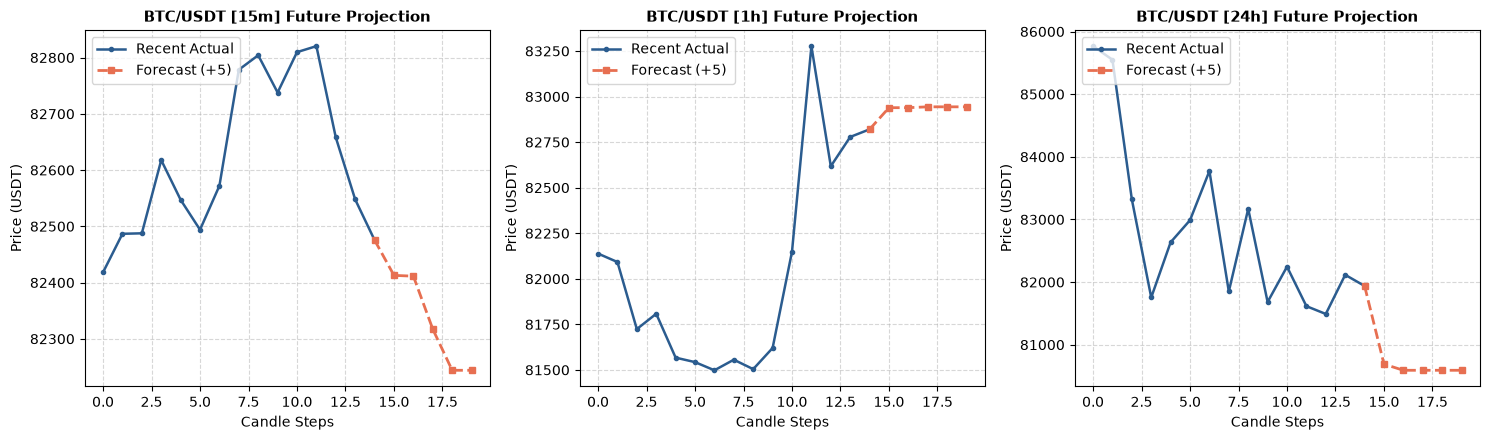

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, tf in zip(axes, ['15m', '1h', '24h']):
    feat_path = f'../data/processed/BTC_USDT_{tf}_features.csv'
    cur_df = pd.read_csv(feat_path)
    cur_split = src.temporal_train_test_split(cur_df, src.FEATURE_COLUMNS)
    cur_models = src.train_and_evaluate_models(cur_split)
    
    best_model = cur_models['LightGBM']['model']
    scaler = cur_split['scaler']
    
    multi_fc = src.multi_step_forecast(best_model, scaler, src.FEATURE_COLUMNS, cur_df, steps=5)
    
    # Plot recent history + forecast
    hist_prices = cur_df['close'].iloc[-15:].values
    pred_prices = [hist_prices[-1]] + list(multi_fc['Simulated_Price'].values)
    
    x_hist = range(len(hist_prices))
    x_pred = range(len(hist_prices) - 1, len(hist_prices) - 1 + len(pred_prices))
    
    ax.plot(x_hist, hist_prices, label='Recent Actual', color='#2b5c8f', lw=1.8, marker='o', markersize=3)
    ax.plot(x_pred, pred_prices, label='Forecast (+5)', color='#e76f51', lw=2.0, linestyle='--', marker='s', markersize=4)
    ax.set_title(f'BTC/USDT [{tf}] Future Projection', fontsize=11, fontweight='bold')
    ax.set_ylabel('Price (USDT)')
    ax.set_xlabel('Candle Steps')
    ax.legend(loc='upper left')
    ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### 📊 Multi-Step Projection Detailed Breakdown

In [4]:
# Display table for 1h multi-step forecast
print("Multi-step forecast trajectory for 1h timeframe:")
multi_fc

Multi-step forecast trajectory for 1h timeframe:


,Step_Ahead,Simulated_Price,Delta_from_Current_$,Return_%
0,+1,80690.36,-1248.04,-1.523
1,+2,80591.93,-98.44,-0.122
2,+3,80591.93,0.00,0.000
3,+4,80591.93,0.00,0.000
4,+5,80591.93,0.00,0.000


### 📝 Project Conclusion & Evaluation Summary
- **Data Coverage:** Successfully analyzed 13 timeframes from 1-minute to 30-day bars.
- **Machine Learning Integration:** Compared Linear Regression, Random Forest, and LightGBM with strict out-of-sample temporal validation.
- **Algorithmic Backtesting:** Simulated $10,000 cash balance incorporating transaction costs and logged every executed trade.
- **Future Forecasting:** Produced multi-timeframe directional signals and projected trajectory cones for decision support.